In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("../data/KC1.csv")

converting target labels into (0/1)

In [3]:
df["Defective"] = df["Defective"].map({
    "b'N'": 0,
    "b'Y'": 1
})

In [4]:
df["Defective"].value_counts()

Defective
0    869
1    314
Name: count, dtype: int64

features are most correlated with defects

In [5]:
corr = df.corr(numeric_only=True)

target_corr = corr["Defective"].sort_values(
    ascending=False
)

print(target_corr)

Defective                1.000000
HALSTEAD_DIFFICULTY      0.274438
NUM_UNIQUE_OPERANDS      0.273088
NUM_UNIQUE_OPERATORS     0.267526
NUM_OPERANDS             0.261050
HALSTEAD_LENGTH          0.252342
HALSTEAD_VOLUME          0.245673
HALSTEAD_ERROR_EST       0.245546
NUM_OPERATORS            0.245479
LOC_BLANK                0.240728
LOC_TOTAL                0.240691
LOC_EXECUTABLE           0.231692
HALSTEAD_CONTENT         0.211936
HALSTEAD_EFFORT          0.207090
HALSTEAD_PROG_TIME       0.207089
DESIGN_COMPLEXITY        0.205226
BRANCH_COUNT             0.203672
CYCLOMATIC_COMPLEXITY    0.200811
LOC_COMMENTS             0.166478
ESSENTIAL_COMPLEXITY     0.136275
LOC_CODE_AND_COMMENT    -0.040227
HALSTEAD_LEVEL          -0.138761
Name: Defective, dtype: float64


How different are defective and non-defective modules

In [6]:
df.groupby("Defective").mean()

,LOC_BLANK,BRANCH_COUNT,LOC_CODE_AND_COMMENT,LOC_COMMENTS,CYCLOMATIC_COMPLEXITY,DESIGN_COMPLEXITY,ESSENTIAL_COMPLEXITY,LOC_EXECUTABLE,HALSTEAD_CONTENT,HALSTEAD_DIFFICULTY,...,HALSTEAD_ERROR_EST,HALSTEAD_LENGTH,HALSTEAD_LEVEL,HALSTEAD_PROG_TIME,HALSTEAD_VOLUME,NUM_OPERANDS,NUM_OPERATORS,NUM_UNIQUE_OPERANDS,NUM_UNIQUE_OPERATORS,LOC_TOTAL
Defective,,,,,,,,,,,,,,,,,,,,,
0,2.261220,5.998849,0.225547,1.226697,3.515535,3.087457,1.925201,19.929804,28.189620,8.809977,...,0.113165,65.920598,0.221450,350.884891,339.442877,24.777906,41.142693,12.667434,9.574223,26.892980
1,4.834395,10.394904,0.143312,2.722930,5.684713,5.009554,2.789809,34.910828,39.375159,14.269076,...,0.230287,123.022293,0.139172,936.677293,691.020892,47.445860,75.576433,21.149682,13.066879,45.949045


Are there extreme outliers?

In [7]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
LOC_BLANK,1183.0,2.944210,4.721904,0.0,0.000,1.00,3.00,58.00
BRANCH_COUNT,1183.0,7.165680,9.534669,1.0,1.000,3.00,9.00,89.00
LOC_CODE_AND_COMMENT,1183.0,0.203719,0.903042,0.0,0.000,0.00,0.00,12.00
LOC_COMMENTS,1183.0,1.623838,3.970237,0.0,0.000,0.00,2.00,44.00
CYCLOMATIC_COMPLEXITY,1183.0,4.091293,4.771792,1.0,1.000,2.00,5.00,45.00
DESIGN_COMPLEXITY,1183.0,3.597633,4.137288,1.0,1.000,2.00,4.00,45.00
ESSENTIAL_COMPLEXITY,1183.0,2.154691,2.802690,1.0,1.000,1.00,1.00,26.00
LOC_EXECUTABLE,1183.0,23.906171,28.562998,0.0,6.000,14.00,33.00,262.00
HALSTEAD_CONTENT,1183.0,31.158563,23.314468,0.0,14.720,25.66,42.58,193.06
HALSTEAD_DIFFICULTY,1183.0,10.258969,8.787196,0.0,3.750,7.71,14.36,53.75


Modules with higher:

LOC_TOTAL<br>
BRANCH_COUNT<br>
CYCLOMATIC_COMPLEXITY<br>
HALSTEAD_EFFORT<br>

will have a higher probability of defects.

Why?

Because larger and more complex code tends to be harder to understand and maintain.

discovered that code complexity and branch density are strong indicators of defect-prone modules.

1. Class Distribution

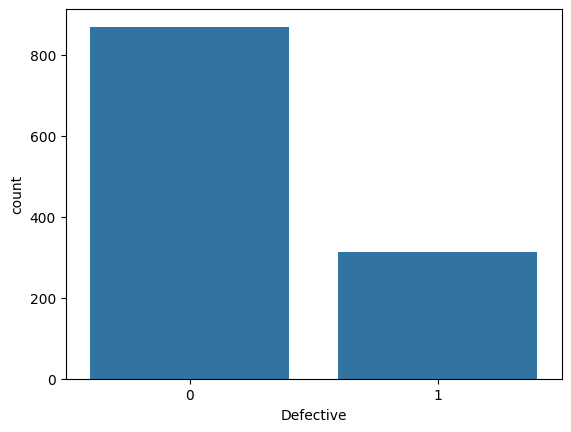

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="Defective", data=df)
plt.show()

2. Correlation Heatmap

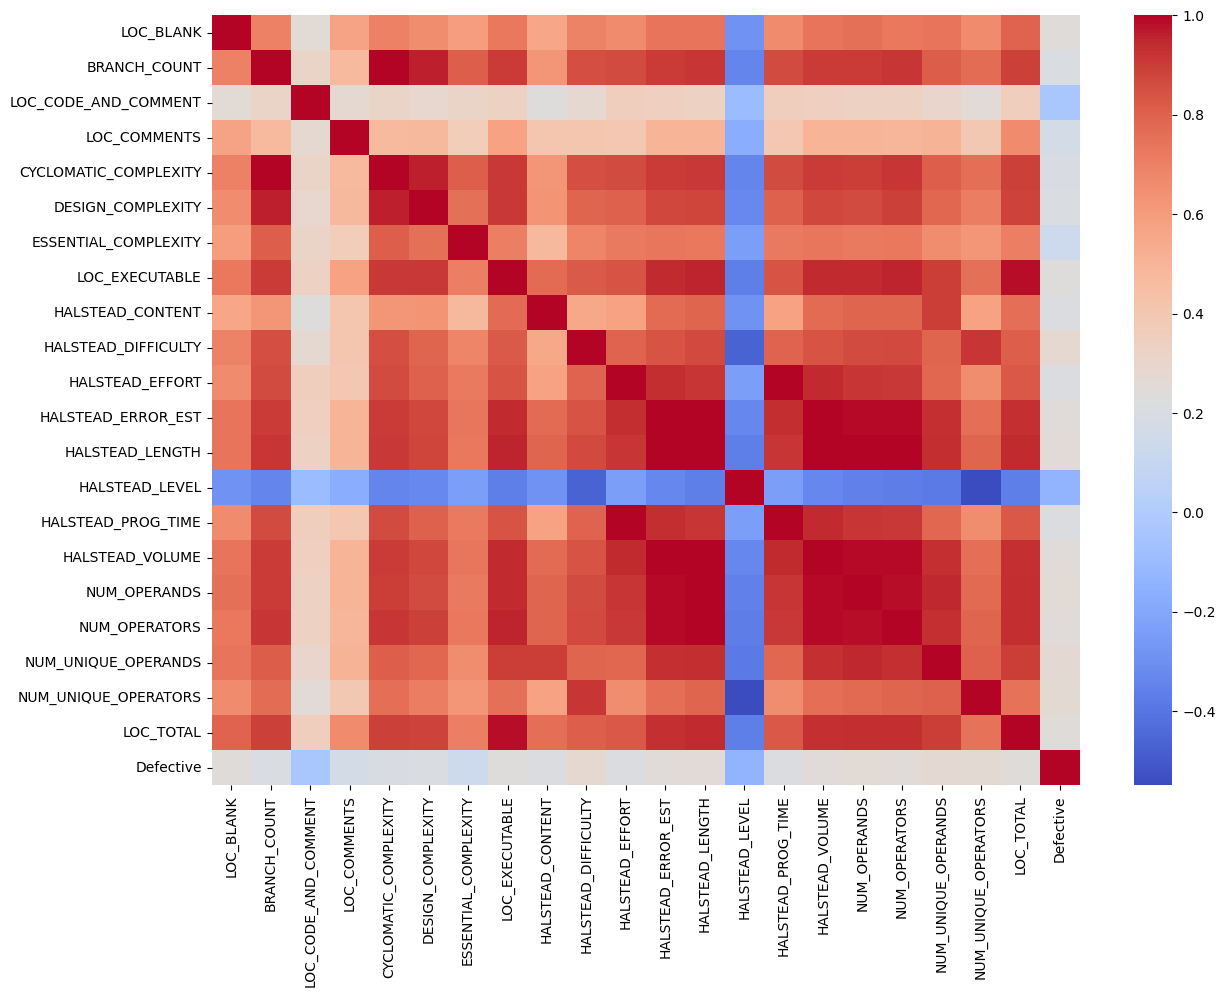

In [9]:
plt.figure(figsize=(14,10))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.show()

3. Distribution Plots

In [10]:
features = [
    "LOC_TOTAL",
    "CYCLOMATIC_COMPLEXITY",
    "HALSTEAD_EFFORT",
    "HALSTEAD_VOLUME"
]

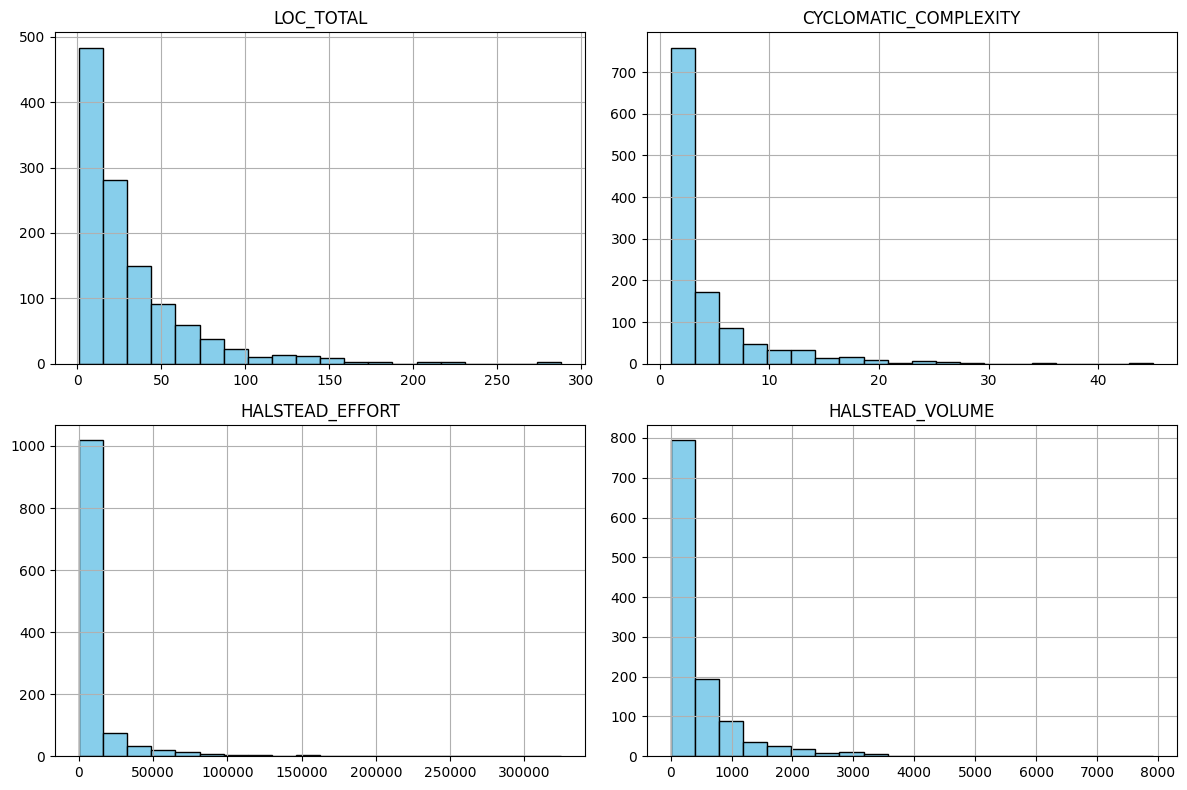

In [12]:
df[features].hist(bins=20, figsize=(12, 8), color="skyblue", edgecolor="black")

plt.tight_layout()
plt.show()